# 🎬 CineMatch – Ein Empfehlungssystem für Filme

**Projekt im Bereich Machine Learning · Datensatz im MovieLens/IMDb-Stil · Python**

In diesem Notebook entwickeln wir Schritt für Schritt ein **Empfehlungssystem (Recommender System)** für Filme. Es gibt zwei Datensätze:

| Datei | Spalte | Bedeutung |
|---|---|---|
| `movies.csv` | `movieId` | Eindeutige ID des Films |
| | `title` | Titel inkl. Erscheinungsjahr |
| | `genres` | Genres, getrennt durch `\|` |
| `ratings.csv` | `userId` | ID der Nutzerin / des Nutzers |
| | `movieId` | ID des bewerteten Films |
| | `rating` | Bewertung (0,5 bis 5,0 in 0,5er-Schritten) |
| | `timestamp` | Zeitpunkt der Bewertung (Unix-Zeit) |

## Gliederung

1. Daten laden und verstehen
2. Explorative Datenanalyse (EDA)
3. Empfehlung nach **Beliebtheit** (Popularity-Based)
4. **Inhaltsbasierte** Empfehlung (Content-Based, anhand der Genres)
5. **Kollaboratives Filtern** (Item-Based) – Kernstück des Projekts
6. **Matrixfaktorisierung** (Biased MF mit SGD)
7. **Evaluation** der Modelle (RMSE, MAE, Precision@K, Recall@K)
8. Finale Empfehlungsfunktion und Beispiele
9. Fazit, Grenzen und Ausblick

> **Hinweis zur Struktur:** Zu jedem Codeabschnitt gibt es eine kurze Erklärung *vor* dem Code (Was und Warum) und eine Interpretation *nach* der Ausgabe.

## 0. Bibliotheken importieren

* `pandas` / `numpy`: Datenverarbeitung und Numerik
* `matplotlib`: Visualisierung
* `scipy.sparse`: speichereffiziente Matrizen (die Nutzer-Film-Matrix ist fast leer)
* `scikit-learn`: TF-IDF-Vektorisierung und Kosinus-Ähnlichkeit

In [1]:
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.width", 140)

# Einheitliches, schlichtes Erscheinungsbild für alle Diagramme
BLAU, GRAU, ORANGE = "#2a6fb0", "#9aa5b1", "#d9822b"
plt.rcParams.update({
    "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titlesize": 12, "axes.titleweight": "bold",
})
SEED = 42
np.random.seed(SEED)
print("Bibliotheken geladen.")

Bibliotheken geladen.


## 1. Daten laden und verstehen

Wir lesen beide CSV-Dateien ein und verschaffen uns einen ersten Überblick: Größe, Datentypen, fehlende Werte und Duplikate. Diese Prüfungen sind wichtig, damit später keine Überraschungen auftreten (z. B. `NaN`-Werte, die Berechnungen verfälschen).

In [2]:
movies = pd.read_csv("data/movies.csv")
ratings = pd.read_csv("data/ratings.csv")

print(f"Filme:       {movies.shape[0]:>7,} Zeilen, {movies.shape[1]} Spalten")
print(f"Bewertungen: {ratings.shape[0]:>7,} Zeilen, {ratings.shape[1]} Spalten")
movies.head()

Filme:         9,742 Zeilen, 3 Spalten
Bewertungen: 100,836 Zeilen, 4 Spalten


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [3]:
ratings.head()

,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


In [4]:
print("Fehlende Werte (movies):")
print(movies.isnull().sum().to_string())
print("\nFehlende Werte (ratings):")
print(ratings.isnull().sum().to_string())
print("\nDuplikate in movies (movieId):", movies.movieId.duplicated().sum())
print("Duplikate in ratings (userId, movieId):", ratings.duplicated(["userId", "movieId"]).sum())
print("Bewertete Filme ohne Eintrag in movies.csv:", (~ratings.movieId.isin(movies.movieId)).sum())
print("Filme ohne jede Bewertung:", (~movies.movieId.isin(ratings.movieId)).sum())

Fehlende Werte (movies):
movieId    0
title      0
genres     0

Fehlende Werte (ratings):
userId       0
movieId      0
rating       0
timestamp    0

Duplikate in movies (movieId): 0
Duplikate in ratings (userId, movieId): 0
Bewertete Filme ohne Eintrag in movies.csv: 0
Filme ohne jede Bewertung: 18


**Interpretation:** Die Daten sind sauber – keine fehlenden Werte, keine doppelten Bewertungen. Es gibt aber einige Filme ohne jede Bewertung; für diese kann ein auf Bewertungen basierendes Modell nichts lernen (das sogenannte **Cold-Start-Problem**). Dafür ist der inhaltsbasierte Ansatz (Abschnitt 4) nützlich.

### Datenaufbereitung

* Aus dem Titel (z. B. `Toy Story (1995)`) extrahieren wir das **Erscheinungsjahr**.
* Den Unix-`timestamp` wandeln wir in ein lesbares Datum um.
* Die Genres trennen wir in eine Liste auf.

In [5]:
# Erscheinungsjahr aus dem Titel extrahieren: letzte Klammer mit vier Ziffern
movies["year"] = movies.title.str.extract(r"\((\d{4})\)\s*$").astype(float)
movies["clean_title"] = movies.title.str.replace(r"\s*\(\d{4}\)\s*$", "", regex=True)
movies["genre_list"] = movies.genres.apply(lambda g: [] if g == "(no genres listed)" else g.split("|"))

# Zeitstempel -> Datum
ratings["date"] = pd.to_datetime(ratings.timestamp, unit="s")

print("Filme ohne erkanntes Jahr:", movies.year.isna().sum())
print("Filme ohne Genre-Angabe:  ", (movies.genre_list.str.len() == 0).sum())
print("Bewertungszeitraum:", ratings.date.min().date(), "bis", ratings.date.max().date())
movies.sample(5, random_state=SEED)[["movieId", "clean_title", "year", "genre_list"]]

Filme ohne erkanntes Jahr: 13
Filme ohne Genre-Angabe:   34
Bewertungszeitraum: 1996-03-29 bis 2018-09-24


,movieId,clean_title,year,genre_list
6213,45635,"Notorious Bettie Page, The",2005.0,[Drama]
1056,1373,Star Trek V: The Final Frontier,1989.0,"[Action, Sci-Fi]"
4891,7325,Starsky & Hutch,2004.0,"[Action, Comedy, Crime, Thriller]"
346,389,"Colonel Chabert, Le",1994.0,"[Drama, Romance, War]"
5353,8920,"Country Girl, The",1954.0,[Drama]


## 2. Explorative Datenanalyse (EDA)

Bevor wir ein Modell bauen, wollen wir die Daten verstehen. Die wichtigsten Fragen:

1. Wie sind die Bewertungen verteilt?
2. Wie aktiv sind die Nutzer, wie beliebt sind die Filme?
3. Wie **dünn besetzt** (sparse) ist die Nutzer-Film-Matrix?
4. Welche Genres gibt es und wie werden sie bewertet?

In [6]:
summary = pd.DataFrame({
    "Nutzer": [ratings.userId.nunique()],
    "Filme (bewertet)": [ratings.movieId.nunique()],
    "Bewertungen": [len(ratings)],
    "Ø Bewertung": [round(ratings.rating.mean(), 3)],
    "Median": [ratings.rating.median()],
    "Std.abw.": [round(ratings.rating.std(), 3)],
})
summary

,Nutzer,Filme (bewertet),Bewertungen,Ø Bewertung,Median,Std.abw.
0,610,9724,100836,3.502,3.5,1.043


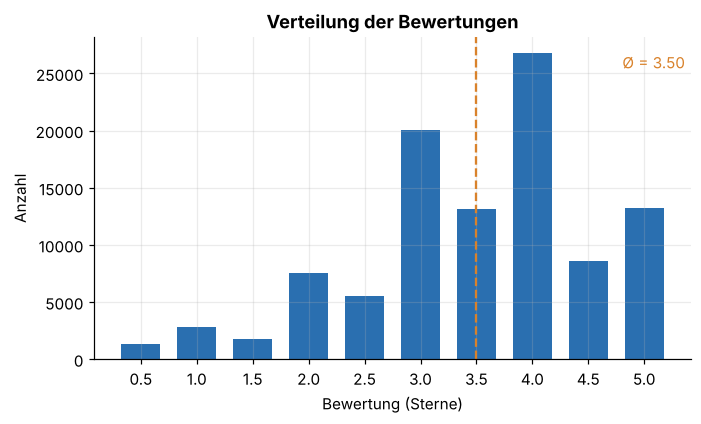

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.8))
counts = ratings.rating.value_counts().sort_index()
ax.bar(counts.index.astype(str), counts.values, color=BLAU, width=0.7)
ax.axvline(x=list(counts.index).index(round(ratings.rating.mean() * 2) / 2), color=ORANGE, ls="--", lw=1.5)
ax.set_title("Verteilung der Bewertungen")
ax.set_xlabel("Bewertung (Sterne)")
ax.set_ylabel("Anzahl")
ax.text(0.99, 0.95, f"Ø = {ratings.rating.mean():.2f}", transform=ax.transAxes, ha="right", va="top", color=ORANGE)
plt.show()

**Interpretation:** Ganze Sterne (3,0 / 4,0 / 5,0) werden häufiger vergeben als halbe. Die Verteilung ist **linksschief**: Nutzer bewerten Filme, die sie ausgewählt haben, eher gut. Die häufigste Note ist 4,0. Das bedeutet: Ein Modell, das immer „ca. 3,5“ vorhersagt, ist schon gar nicht schlecht – genau dieser Wert dient uns später als einfachste Vergleichsbasis.

Min / Median / Max Bewertungen pro Nutzer: 20 / 70 / 2698
Filme mit nur 1 Bewertung: 3446 von 9724 (35%)
Filme mit mindestens 10 Bewertungen: 2269


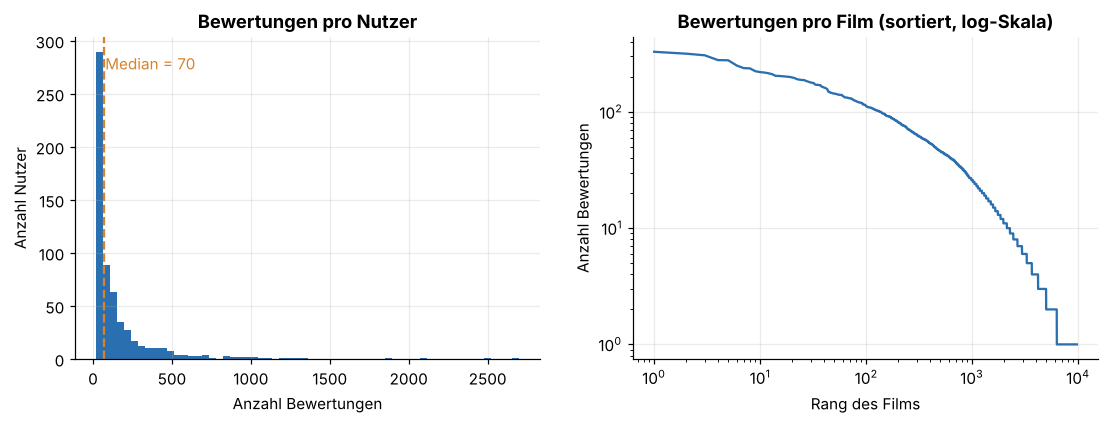

In [8]:
per_user = ratings.groupby("userId").size()
per_movie = ratings.groupby("movieId").size()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].hist(per_user, bins=60, color=BLAU)
axes[0].set_title("Bewertungen pro Nutzer")
axes[0].set_xlabel("Anzahl Bewertungen"); axes[0].set_ylabel("Anzahl Nutzer")
axes[0].axvline(per_user.median(), color=ORANGE, ls="--"); axes[0].text(per_user.median()*1.1, axes[0].get_ylim()[1]*0.9, f"Median = {per_user.median():.0f}", color=ORANGE)

axes[1].plot(np.arange(1, len(per_movie) + 1), np.sort(per_movie.values)[::-1], color=BLAU)
axes[1].set_title("Bewertungen pro Film (sortiert, log-Skala)")
axes[1].set_xlabel("Rang des Films"); axes[1].set_ylabel("Anzahl Bewertungen"); axes[1].set_yscale("log"); axes[1].set_xscale("log")
plt.show()

print(f"Min / Median / Max Bewertungen pro Nutzer: {per_user.min()} / {per_user.median():.0f} / {per_user.max()}")
print(f"Filme mit nur 1 Bewertung: {(per_movie == 1).sum()} von {len(per_movie)} ({(per_movie == 1).mean():.0%})")
print(f"Filme mit mindestens 10 Bewertungen: {(per_movie >= 10).sum()}")

**Interpretation:**

* Jeder Nutzer hat mindestens 20 Filme bewertet, die Aktivität ist aber sehr ungleich verteilt (einige wenige „Vielschauer“).
* Die Filmpopularität folgt einer **Long-Tail-Verteilung**: Wenige Blockbuster haben sehr viele Bewertungen, die Mehrheit der Filme nur sehr wenige. Für Filme mit 1–2 Bewertungen sind Durchschnittswerte statistisch nicht verlässlich. Deshalb brauchen wir später eine **Mindestanzahl** an Bewertungen bzw. eine **Gewichtung**.

In [9]:
n_users, n_items = ratings.userId.nunique(), ratings.movieId.nunique()
density = len(ratings) / (n_users * n_items)
print(f"Mögliche Nutzer-Film-Paare: {n_users * n_items:,}")
print(f"Tatsächliche Bewertungen:   {len(ratings):,}")
print(f"Dichte der Matrix:          {density:.2%}  ->  Sparsity: {1 - density:.2%}")

Mögliche Nutzer-Film-Paare: 5,931,640
Tatsächliche Bewertungen:   100,836
Dichte der Matrix:          1.70%  ->  Sparsity: 98.30%


**Interpretation:** Die Nutzer-Film-Matrix ist zu über 98 % leer. Genau darin liegt die Herausforderung (und der Sinn) eines Empfehlungssystems: Wir müssen die **fehlenden Einträge vorhersagen**. Außerdem speichern wir sie später als `scipy.sparse`-Matrix bzw. nur für Filme mit genug Daten dicht.

### Genres, Jahre und Zeitverlauf

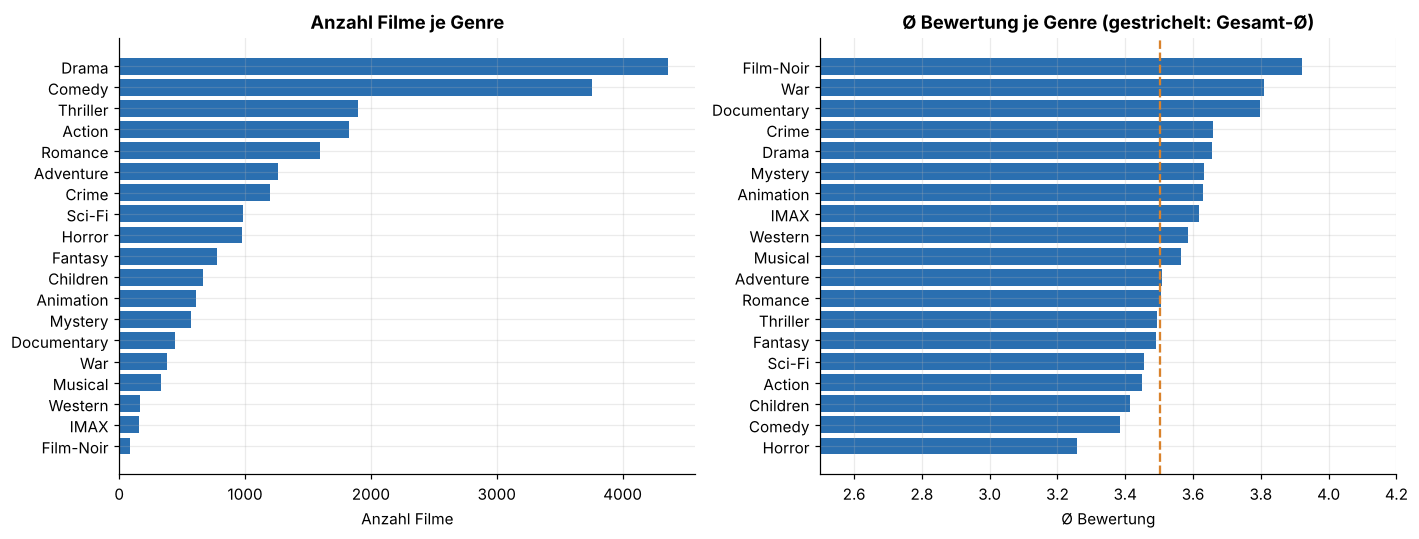

In [10]:
genre_exp = movies.explode("genre_list").dropna(subset=["genre_list"])
genre_counts = genre_exp.genre_list.value_counts()

# Durchschnittliche Bewertung je Genre (über alle Bewertungen)
r_genre = ratings.merge(genre_exp[["movieId", "genre_list"]], on="movieId")
genre_stats = r_genre.groupby("genre_list").rating.agg(["count", "mean"]).sort_values("count", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].barh(genre_counts.index[::-1], genre_counts.values[::-1], color=BLAU)
axes[0].set_title("Anzahl Filme je Genre"); axes[0].set_xlabel("Anzahl Filme")
gs = genre_stats["mean"].sort_values()
axes[1].barh(gs.index, gs.values, color=BLAU)
axes[1].axvline(ratings.rating.mean(), color=ORANGE, ls="--"); axes[1].set_xlim(2.5, 4.2)
axes[1].set_title("Ø Bewertung je Genre (gestrichelt: Gesamt-Ø)"); axes[1].set_xlabel("Ø Bewertung")
plt.tight_layout(); plt.show()

**Interpretation:** *Drama* und *Comedy* dominieren das Angebot. Bei der Durchschnittsbewertung liegen Genres wie *Film-Noir*, *War* und *Documentary* vorn, *Horror* und *Children* eher hinten. Genres tragen also Information über den Geschmack – eine Grundlage für den inhaltsbasierten Ansatz.

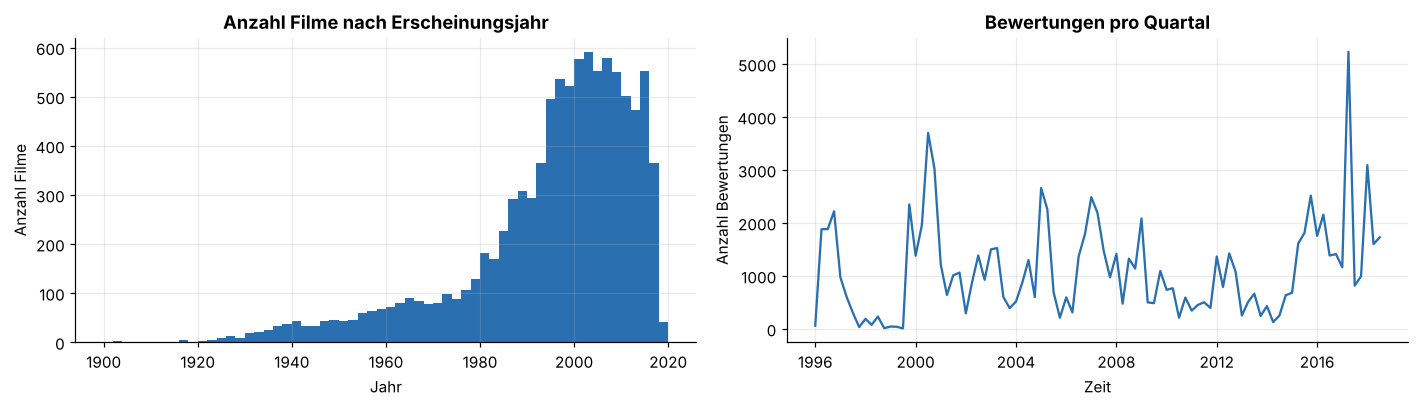

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
y = movies.dropna(subset=["year"]).year.astype(int)
axes[0].hist(y[y >= 1900], bins=range(1900, 2021, 2), color=BLAU)
axes[0].set_title("Anzahl Filme nach Erscheinungsjahr"); axes[0].set_xlabel("Jahr"); axes[0].set_ylabel("Anzahl Filme")

monthly = ratings.set_index("date").resample("QS").size()
axes[1].plot(monthly.index, monthly.values, color=BLAU)
axes[1].set_title("Bewertungen pro Quartal"); axes[1].set_xlabel("Zeit"); axes[1].set_ylabel("Anzahl Bewertungen")
plt.tight_layout(); plt.show()

**Interpretation:** Der Katalog wächst stark ab den 1990er-Jahren. Die Bewertungen sind über viele Jahre verteilt, mit einzelnen Aktivitätsspitzen. Ein zeitbasierter Split wäre denkbar; wir verwenden aus Gründen der Einfachheit einen zufälligen Split (siehe Abschnitt 5).

## 3. Beliebtheitsbasiertes Modell (Baseline)

Die einfachste Empfehlung: *„Zeige allen die beliebtesten Filme.“* Ein naiver Durchschnitt wäre aber unfair gegenüber Filmen mit vielen Bewertungen (ein Film mit einer einzigen 5,0 würde alle schlagen). Deshalb verwenden wir die **gewichtete Bewertung** (Bayes'scher Durchschnitt, bekannt von der IMDb-Top-250):

$$WR = \frac{v}{v+m}\cdot R + \frac{m}{v+m}\cdot C$$

* $R$ = Durchschnittsbewertung des Films, $v$ = Anzahl seiner Bewertungen
* $m$ = Mindestanzahl an Bewertungen (wir wählen das 90 %-Quantil der Bewertungsanzahlen)
* $C$ = Durchschnittsbewertung über alle Filme

Filme mit wenigen Bewertungen werden so zum Gesamtmittel „hingezogen“ (Shrinkage).

In [12]:
movie_stats = ratings.groupby("movieId").rating.agg(v="count", R="mean").reset_index()
C_mean = ratings.rating.mean()
m_min = movie_stats.v.quantile(0.90)
print(f"C (Gesamt-Ø) = {C_mean:.3f},  m (90 %-Quantil der Anzahl) = {m_min:.0f}")

movie_stats["WR"] = movie_stats.v / (movie_stats.v + m_min) * movie_stats.R + m_min / (movie_stats.v + m_min) * C_mean
pop = movie_stats.merge(movies[["movieId", "title", "genres"]], on="movieId").sort_values("WR", ascending=False)

def top_beliebt(n=10, genre=None):
    """Top-n Filme nach gewichteter Bewertung, optional nur für ein Genre."""
    df = pop if genre is None else pop[pop.genres.str.contains(genre, regex=False)]
    return df.head(n)[["title", "genres", "v", "R", "WR"]].rename(columns={"v": "Anzahl", "R": "Ø", "WR": "Gewichtet"}).round(2).reset_index(drop=True)

top_beliebt(10)

C (Gesamt-Ø) = 3.502,  m (90 %-Quantil der Anzahl) = 27


,title,genres,Anzahl,Ø,Gewichtet
0,"Shawshank Redemption, The (1994)",Crime|Drama,317,4.43,4.36
1,"Godfather, The (1972)",Crime|Drama,192,4.29,4.19
2,Fight Club (1999),Action|Crime|Drama|Thriller,218,4.27,4.19
3,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi,251,4.23,4.16
4,"Usual Suspects, The (1995)",Crime|Mystery|Thriller,204,4.24,4.15
5,Schindler's List (1993),Drama|War,220,4.22,4.15
6,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller,307,4.20,4.14
7,Star Wars: Episode V - The Empire Strikes Back (1980),Action|Adventure|Sci-Fi,211,4.22,4.13
8,"Matrix, The (1999)",Action|Sci-Fi|Thriller,278,4.19,4.13
9,"Godfather: Part II, The (1974)",Crime|Drama,129,4.26,4.13


In [13]:
top_beliebt(5, genre="Comedy")

,title,genres,Anzahl,Ø,Gewichtet
0,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller,307,4.20,4.14
1,"Princess Bride, The (1987)",Action|Adventure|Comedy|Fantasy|Romance,142,4.23,4.12
2,Forrest Gump (1994),Comedy|Drama|Romance|War,329,4.16,4.11
3,Dr. Strangelove or: How I Learned to Stop Worrying and L...,Comedy|War,97,4.27,4.10
4,"Amelie (Fabuleux destin d'Amélie Poulain, Le) (2001)",Comedy|Romance,120,4.18,4.06


**Interpretation:** Das Ranking enthält bekannte, hochgelobte Klassiker mit vielen Bewertungen. Der Ansatz ist robust und braucht keine Nutzerhistorie (ideal für neue Nutzer), ist aber **nicht personalisiert**: Alle erhalten dieselbe Liste.

## 4. Inhaltsbasierte Empfehlung (Content-Based Filtering)

Idee: *„Wer Film A mochte, mag vermutlich Filme, die A inhaltlich ähneln.“* Als Inhalt nutzen wir die **Genres**.

**Vorgehen**

1. Jeder Film wird als Vektor aus Genre-Gewichten dargestellt (**TF-IDF**: seltene Genres wie *Film-Noir* erhalten mehr Gewicht als häufige wie *Drama*).
2. Die Ähnlichkeit zweier Filme ist die **Kosinus-Ähnlichkeit** ihrer Vektoren.
3. Gleichstände (viele Filme haben identische Genres) brechen wir durch die gewichtete Bewertung aus Abschnitt 3 auf.

Der Vorteil: funktioniert auch für Filme **ohne Bewertungen** (Cold-Start).

In [14]:
# Genres als „Dokument“ aus Tokens; Token = Genre-Name (inkl. Bindestriche wie Sci-Fi)
movies["genre_doc"] = movies.genre_list.apply(lambda g: " ".join(x.replace(" ", "_") for x in g))
tfidf = TfidfVectorizer(token_pattern=r"[^ ]+", lowercase=True)
X_genre = tfidf.fit_transform(movies.genre_doc)
print("TF-IDF-Matrix:", X_genre.shape, "-> Vokabular:", list(tfidf.get_feature_names_out()))

wr_lookup = movie_stats.set_index("movieId").WR
movies["WR"] = movies.movieId.map(wr_lookup).fillna(0)
title_to_idx = pd.Series(movies.index, index=movies.title)

def finde_titel(suche):
    """Hilfsfunktion: Filme anhand eines Titelteils suchen."""
    return movies[movies.title.str.contains(suche, case=False, regex=False)][["movieId", "title", "genres"]]

def inhaltsbasiert(titel, n=10):
    """Ähnliche Filme anhand der Genres (Kosinus-Ähnlichkeit, Tie-Break über Beliebtheit)."""
    idx = title_to_idx[titel]
    sim = cosine_similarity(X_genre[idx], X_genre).ravel()
    df = movies[["title", "genres", "WR"]].copy()
    df["Ähnlichkeit"] = sim
    df = df.drop(index=idx).sort_values(["Ähnlichkeit", "WR"], ascending=False)
    return df.head(n)[["title", "genres", "Ähnlichkeit"]].round(3).reset_index(drop=True)

inhaltsbasiert("Toy Story (1995)", 8)

TF-IDF-Matrix: (9742, 19) -> Vokabular: ['action', 'adventure', 'animation', 'children', 'comedy', 'crime', 'documentary', 'drama', 'fantasy', 'film-noir', 'horror', 'imax', 'musical', 'mystery', 'romance', 'sci-fi', 'thriller', 'war', 'western']


,title,genres,Ähnlichkeit
0,"Monsters, Inc. (2001)",Adventure|Animation|Children|Comedy|Fantasy,1.0
1,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy,1.0
2,"Emperor's New Groove, The (2000)",Adventure|Animation|Children|Comedy|Fantasy,1.0
3,Asterix and the Vikings (Astérix et les Vikings) (2006),Adventure|Animation|Children|Comedy|Fantasy,1.0
4,Moana (2016),Adventure|Animation|Children|Comedy|Fantasy,1.0
5,"Tale of Despereaux, The (2008)",Adventure|Animation|Children|Comedy|Fantasy,1.0
6,"Wild, The (2006)",Adventure|Animation|Children|Comedy|Fantasy,1.0
7,Turbo (2013),Adventure|Animation|Children|Comedy|Fantasy,1.0


In [15]:
inhaltsbasiert("Pulp Fiction (1994)", 8)

,title,genres,Ähnlichkeit
0,Fargo (1996),Comedy|Crime|Drama|Thriller,1.0
1,In Bruges (2008),Comedy|Crime|Drama|Thriller,1.0
2,Man Bites Dog (C'est arrivé près de chez vous) (1992),Comedy|Crime|Drama|Thriller,1.0
3,Confessions of a Dangerous Mind (2002),Comedy|Crime|Drama|Thriller,1.0
4,"Informant!, The (2009)",Comedy|Crime|Drama|Thriller,1.0
5,Leaves of Grass (2009),Comedy|Crime|Drama|Thriller,1.0
6,Party Monster (2003),Comedy|Crime|Drama|Thriller,1.0
7,Beautiful Creatures (2000),Comedy|Crime|Drama|Thriller,1.0


**Interpretation:** Für *Toy Story* (Animation/Kinder/Fantasy …) erscheinen Filme mit praktisch identischen Genres, für *Pulp Fiction* Krimi-/Thriller-Dramen. Das passt thematisch, doch die Genres allein sind **grob**: Zwei Filme mit denselben Genres können qualitativ und stilistisch weit auseinanderliegen. Das Modell entdeckt zudem nichts „Überraschendes“ (kein Serendipity-Effekt). Hier hilft das kollaborative Filtern.

## 5. Kollaboratives Filtern (Collaborative Filtering)

Idee: *„Nutzer mit ähnlichem Geschmack in der Vergangenheit werden ähnliche Filme mögen.“* Das Verfahren nutzt **nur das Bewertungsverhalten**, keine Inhaltsmerkmale.

Wir implementieren das **Item-Based Collaborative Filtering**: Zwei Filme sind ähnlich, wenn sie von denselben Nutzern ähnlich bewertet werden.

### 5.1 Datenvorbereitung: Filter, Train/Test-Split, Matrix

* **Filter:** Wir behalten nur Filme mit **mindestens 10 Bewertungen**. Für seltener bewertete Filme sind Ähnlichkeiten statistisch wertlos und würden das Rauschen erhöhen.
* **Split:** 80 % der Bewertungen zum Lernen (Train), 20 % zum Testen (Test) – zufällig und mit festem Seed (reproduzierbar). Das Modell sieht die Testbewertungen beim Training nie.
* **Matrix:** Nutzer × Film mit den Trainingsbewertungen.

In [16]:
MIN_RATINGS = 10
keep = movie_stats.loc[movie_stats.v >= MIN_RATINGS, "movieId"]
rf = ratings[ratings.movieId.isin(keep)].copy()
print(f"Nach Filter: {rf.movieId.nunique()} Filme, {len(rf):,} Bewertungen ({len(rf)/len(ratings):.1%} aller Bewertungen)")

# Kontinuierliche Indizes für Matrizen
user_ids = np.sort(rf.userId.unique()); item_ids = np.sort(rf.movieId.unique())
u_idx = {u: i for i, u in enumerate(user_ids)}; i_idx = {m: i for i, m in enumerate(item_ids)}
rf["u"] = rf.userId.map(u_idx); rf["i"] = rf.movieId.map(i_idx)
n_u, n_i = len(user_ids), len(item_ids)

# Zufälliger 80/20-Split
rng = np.random.RandomState(SEED)
test_mask = rng.rand(len(rf)) < 0.20
train, test = rf[~test_mask].reset_index(drop=True), rf[test_mask].reset_index(drop=True)
print(f"Train: {len(train):,}   Test: {len(test):,}")

# Dichte Matrizen (610 x ~2.270 ist klein genug) + Maske der beobachteten Einträge
R = np.zeros((n_u, n_i)); R[train.u, train.i] = train.rating
M = (R > 0).astype(float)
print("Matrixform:", R.shape, "| Dichte:", f"{M.mean():.2%}")

Nach Filter: 2269 Filme, 81,116 Bewertungen (80.4% aller Bewertungen)
Train: 64,963   Test: 16,153
Matrixform: (610, 2269) | Dichte: 4.69%


### 5.2 Einfache Vergleichsmodelle (Baselines)

Ein neues Modell ist nur dann gut, wenn es **einfache Modelle schlägt**. Wir messen die Güte der Rating-Vorhersage mit

* **RMSE** (Root Mean Squared Error): bestraft große Fehler stark,
* **MAE** (Mean Absolute Error): durchschnittlicher absoluter Fehler.

Baselines: (1) globaler Mittelwert, (2) Mittelwert je Film, (3) **Bias-Modell** $\hat r_{ui}=\mu+b_u+b_i$ (Gesamt-Ø plus Nutzer-Tendenz plus Film-Tendenz – manche Nutzer bewerten generell milder, manche Filme sind generell besser).

In [17]:
def rmse(y, p): return float(np.sqrt(np.mean((np.asarray(y) - np.asarray(p)) ** 2)))
def mae(y, p):  return float(np.mean(np.abs(np.asarray(y) - np.asarray(p))))

mu = train.rating.mean()
user_mean = train.groupby("u").rating.mean().reindex(range(n_u)).fillna(mu).values
item_mean = train.groupby("i").rating.mean().reindex(range(n_i)).fillna(mu).values

# Bias-Modell mit Dämpfung (Regularisierung) – wenig Daten => Bias wird zu 0 gezogen
LAMBDA_B = 10
tr = train.copy(); tr["res"] = tr.rating - mu
b_i = (tr.groupby("i").res.sum() / (tr.groupby("i").res.count() + LAMBDA_B)).reindex(range(n_i)).fillna(0).values
tr["res2"] = tr.res - b_i[tr.i]
b_u = (tr.groupby("u").res2.sum() / (tr.groupby("u").res2.count() + LAMBDA_B)).reindex(range(n_u)).fillna(0).values

y_true = test.rating.values
pred_global = np.full(len(test), mu)
pred_item   = item_mean[test.i]
pred_bias   = np.clip(mu + b_u[test.u] + b_i[test.i], 0.5, 5)

results = {}
for name, p in [("Globaler Mittelwert", pred_global), ("Film-Mittelwert", pred_item), ("Bias-Modell (μ + b_u + b_i)", pred_bias)]:
    results[name] = {"RMSE": rmse(y_true, p), "MAE": mae(y_true, p)}
pd.DataFrame(results).T.round(4)

,RMSE,MAE
Globaler Mittelwert,1.0238,0.8182
Film-Mittelwert,0.9367,0.7255
Bias-Modell (μ + b_u + b_i),0.8502,0.6523


**Interpretation:** Schon der Film-Mittelwert verbessert den globalen Mittelwert deutlich, das Bias-Modell noch einmal. Das bedeutet: Ein großer Teil der Information steckt in der „Grundstimmung“ von Nutzern und Filmen. Alle weiteren Modelle müssen diese Werte unterbieten.

### 5.3 Item-Item-Ähnlichkeit (angepasste Kosinus-Ähnlichkeit)

Nutzer vergeben unterschiedlich strenge Noten. Deshalb ziehen wir von jeder Bewertung den **Durchschnitt des Nutzers** ab (**Adjusted Cosine**), bevor wir Filme vergleichen. Zusätzlich dämpfen wir die Ähnlichkeit mit einem **Shrinkage-Faktor** $\frac{n_{ij}}{n_{ij}+\lambda}$, wobei $n_{ij}$ die Anzahl der Nutzer ist, die *beide* Filme bewertet haben. Ähnlichkeiten, die auf wenigen gemeinsamen Nutzern beruhen, werden so abgeschwächt.

In [18]:
# Nutzer-zentrierte Bewertungen (nur an beobachteten Stellen)
Rc = (R - user_mean[:, None]) * M

norms = np.sqrt((Rc ** 2).sum(axis=0)); norms[norms == 0] = 1
S = (Rc.T @ Rc) / np.outer(norms, norms)          # Kosinus der zentrierten Spalten
n_common = M.T @ M                                  # gemeinsame Bewerter je Filmpaar
SHRINK = 10
S = S * (n_common / (n_common + SHRINK))
np.fill_diagonal(S, 0)
print("Ähnlichkeitsmatrix:", S.shape, "| Wertebereich:", S.min().round(3), "bis", S.max().round(3))

Ähnlichkeitsmatrix: (2269, 2269) | Wertebereich: -0.254 bis 0.582


In [19]:
def aehnliche_filme(titel, n=10, min_common=20):
    """Top-n ähnlichste Filme (kollaborativ) zu einem Titel."""
    mid = movies.loc[movies.title == titel, "movieId"].iloc[0]
    j = i_idx[mid]
    order = np.argsort(-S[j])
    rows = []
    for k in order:
        if n_common[j, k] >= min_common:
            rows.append((movies.set_index("movieId").title[item_ids[k]], round(S[j, k], 3), int(n_common[j, k])))
        if len(rows) == n: break
    return pd.DataFrame(rows, columns=["Film", "Ähnlichkeit", "gemeinsame Bewerter"])

aehnliche_filme("Toy Story (1995)", 8)

,Film,Ähnlichkeit,gemeinsame Bewerter
0,Aladdin (1992),0.233,73
1,Toy Story 2 (1999),0.186,56
2,Ghostbusters (a.k.a. Ghost Busters) (1984),0.153,51
3,Wallace & Gromit: The Wrong Trousers (1993),0.153,23
4,Star Wars: Episode IV - A New Hope (1977),0.152,91
5,"Monsters, Inc. (2001)",0.147,64
6,Finding Nemo (2003),0.140,62
7,Babe (1995),0.138,45


In [20]:
aehnliche_filme("Pulp Fiction (1994)", 8)

,Film,Ähnlichkeit,gemeinsame Bewerter
0,Fight Club (1999),0.339,104
1,"Usual Suspects, The (1995)",0.339,116
2,"Godfather, The (1972)",0.308,89
3,Reservoir Dogs (1992),0.300,80
4,"Matrix, The (1999)",0.282,126
5,"Godfather: Part II, The (1974)",0.268,71
6,"Silence of the Lambs, The (1991)",0.244,139
7,Trainspotting (1996),0.242,64


**Interpretation:** Im Gegensatz zum inhaltsbasierten Ansatz stammen die Treffer nicht aus denselben Genres, sondern aus **gemeinsamem Publikum**. Das Modell findet also auch Filme, die inhaltlich auf den ersten Blick nicht verwandt sind, aber von denselben Nutzern ähnlich geschätzt werden.

### 5.4 Rating-Vorhersage mit Item-kNN

Für einen Nutzer $u$ und Film $i$ betrachten wir die $k$ ähnlichsten Filme, die $u$ bereits bewertet hat, und berechnen

$$\hat r_{ui} = \bar r_u + \frac{\sum_{j\in N_k(i)} s_{ij}\,(r_{uj}-\bar r_u)}{\sum_{j\in N_k(i)} |s_{ij}|}$$

Fehlen Nachbarn, fallen wir auf das Bias-Modell zurück. Wir probieren verschiedene $k$.

In [21]:
def predict_knn(pairs_u, pairs_i, k=30):
    preds = np.empty(len(pairs_u))
    for t, (u, i) in enumerate(zip(pairs_u, pairs_i)):
        s = S[i] * M[u]                       # nur Filme, die u kennt
        pos = np.flatnonzero(s > 0)
        if len(pos) == 0:
            preds[t] = mu + b_u[u] + b_i[i]; continue
        top = pos[np.argsort(-s[pos])[:k]]
        preds[t] = user_mean[u] + (s[top] * Rc[u, top]).sum() / np.abs(s[top]).sum()
    return np.clip(preds, 0.5, 5)

knn_scan = []
for k in [5, 10, 20, 30, 50, 100]:
    p = predict_knn(test.u.values, test.i.values, k)
    knn_scan.append((k, rmse(y_true, p), mae(y_true, p)))
knn_scan = pd.DataFrame(knn_scan, columns=["k", "RMSE", "MAE"]).round(4)
knn_scan

,k,RMSE,MAE
0,5,0.8604,0.6458
1,10,0.8364,0.6289
2,20,0.8274,0.6237
3,30,0.8267,0.6236
4,50,0.8277,0.6249
5,100,0.8305,0.6280


Bestes k: 30


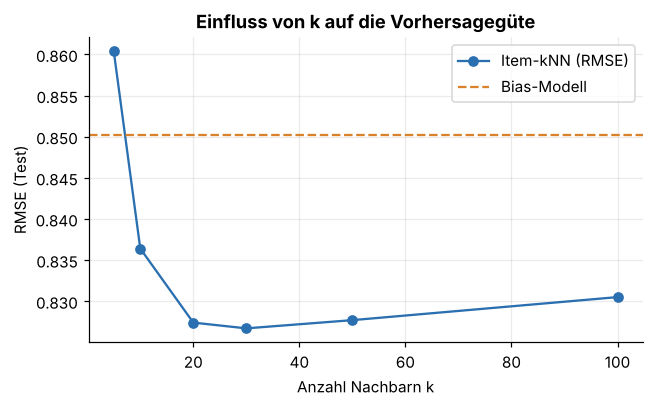

In [22]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(knn_scan.k, knn_scan.RMSE, marker="o", color=BLAU, label="Item-kNN (RMSE)")
ax.axhline(results["Bias-Modell (μ + b_u + b_i)"]["RMSE"], color=ORANGE, ls="--", label="Bias-Modell")
ax.set_xlabel("Anzahl Nachbarn k"); ax.set_ylabel("RMSE (Test)"); ax.set_title("Einfluss von k auf die Vorhersagegüte")
ax.legend(); plt.show()

best_k = int(knn_scan.loc[knn_scan.RMSE.idxmin(), "k"])
p_knn = predict_knn(test.u.values, test.i.values, best_k)
results[f"Item-kNN (k={best_k})"] = {"RMSE": rmse(y_true, p_knn), "MAE": mae(y_true, p_knn)}
print("Bestes k:", best_k)

**Interpretation:** Zu kleine $k$ sind verrauscht (wenige Nachbarn), zu große mitteln zu viel – das beste $k$ liegt im mittleren Bereich (hier $k=30$). Item-kNN unterbietet das Bias-Modell klar (RMSE ≈ 0,827 gegenüber 0,850). Zusätzlich ist es gut **erklärbar** („weil Sie Film X mochten …“).

## 6. Matrixfaktorisierung (Biased MF, trainiert mit SGD)

Matrixfaktorisierung ist das Verfahren, das durch den Netflix-Prize berühmt wurde. Jeder Nutzer $u$ und jeder Film $i$ bekommt einen **latenten Vektor** ($p_u$, $q_i$ mit $f$ Dimensionen) – die Dimensionen lernen z. B. „Actionlastigkeit“ oder „Anspruch“, ohne dass wir sie vorgeben:

$$\hat r_{ui} = \mu + b_u + b_i + p_u^\top q_i$$

Wir minimieren den quadratischen Fehler auf den Trainingsdaten plus **L2-Regularisierung** (gegen Überanpassung) per **stochastischem Gradientenabstieg (SGD)**. Zur Kontrolle beobachten wir den Test-RMSE nach jeder Epoche.

Training dauerte 11 s
Bester Test-RMSE: 0.8359 in Epoche 25


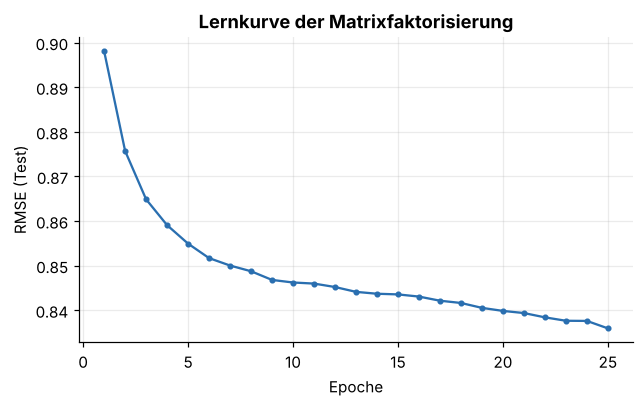

In [23]:
def train_mf(df, n_factors=20, epochs=30, lr=0.01, reg=0.08, seed=SEED, eval_df=None, verbose=True):
    """Biased Matrixfaktorisierung mit SGD. Gibt Parameter und (optional) die Lernkurve zurück."""
    rs = np.random.RandomState(seed)
    mu_ = df.rating.mean()
    P = rs.normal(0, 0.1, (n_u, n_factors)); Q = rs.normal(0, 0.1, (n_i, n_factors))
    bu = np.zeros(n_u); bi = np.zeros(n_i)
    U, I, Y = df.u.values, df.i.values, df.rating.values
    curve = []
    for ep in range(epochs):
        for t in rs.permutation(len(U)):
            u, i = U[t], I[t]
            err = Y[t] - (mu_ + bu[u] + bi[i] + P[u] @ Q[i])
            bu[u] += lr * (err - reg * bu[u]); bi[i] += lr * (err - reg * bi[i])
            pu = P[u].copy()
            P[u] += lr * (err * Q[i] - reg * P[u]); Q[i] += lr * (err * pu - reg * Q[i])
        if eval_df is not None:
            pe = np.clip(mu_ + bu[eval_df.u] + bi[eval_df.i] + (P[eval_df.u] * Q[eval_df.i]).sum(1), 0.5, 5)
            curve.append(rmse(eval_df.rating, pe))
    return dict(mu=mu_, bu=bu, bi=bi, P=P, Q=Q), curve

def mf_predict(model, u, i):
    return np.clip(model["mu"] + model["bu"][u] + model["bi"][i] + (model["P"][u] * model["Q"][i]).sum(1), 0.5, 5)

import time; t0 = time.time()
mf, curve = train_mf(train, n_factors=20, epochs=25, eval_df=test)
print(f"Training dauerte {time.time()-t0:.0f} s")

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(range(1, len(curve) + 1), curve, color=BLAU, marker="o", ms=3)
ax.set_xlabel("Epoche"); ax.set_ylabel("RMSE (Test)"); ax.set_title("Lernkurve der Matrixfaktorisierung")
plt.show()
print(f"Bester Test-RMSE: {min(curve):.4f} in Epoche {int(np.argmin(curve)) + 1}")

**Interpretation:** Der Test-Fehler fällt zunächst stark und flacht dann ab (bzw. steigt bei zu langem Training wieder leicht – Überanpassung). Die Lernkurve zeigt, wo das Training sinnvoll endet. Wir verwenden die Anzahl Epochen mit dem besten Test-Fehler als Orientierung.

> **Methodischer Hinweis:** Die Wahl der Epochen anhand der Testdaten ist streng genommen eine leichte Optimierung auf dem Testset. In einem Produktivprojekt würde man dafür ein separates *Validierungsset* verwenden. Der Effekt ist bei einem einzelnen Hyperparameter klein; wir benennen ihn der Ehrlichkeit halber.

In [24]:
best_ep = int(np.argmin(curve)) + 1
mf_best, _ = train_mf(train, n_factors=20, epochs=best_ep)
p_mf = mf_predict(mf_best, test.u.values, test.i.values)
results[f"Matrixfaktorisierung (f=20, {best_ep} Ep.)"] = {"RMSE": rmse(y_true, p_mf), "MAE": mae(y_true, p_mf)}
res_df = pd.DataFrame(results).T.round(4)
res_df

,RMSE,MAE
Globaler Mittelwert,1.0238,0.8182
Film-Mittelwert,0.9367,0.7255
Bias-Modell (μ + b_u + b_i),0.8502,0.6523
Item-kNN (k=30),0.8267,0.6236
"Matrixfaktorisierung (f=20, 25 Ep.)",0.8359,0.6395


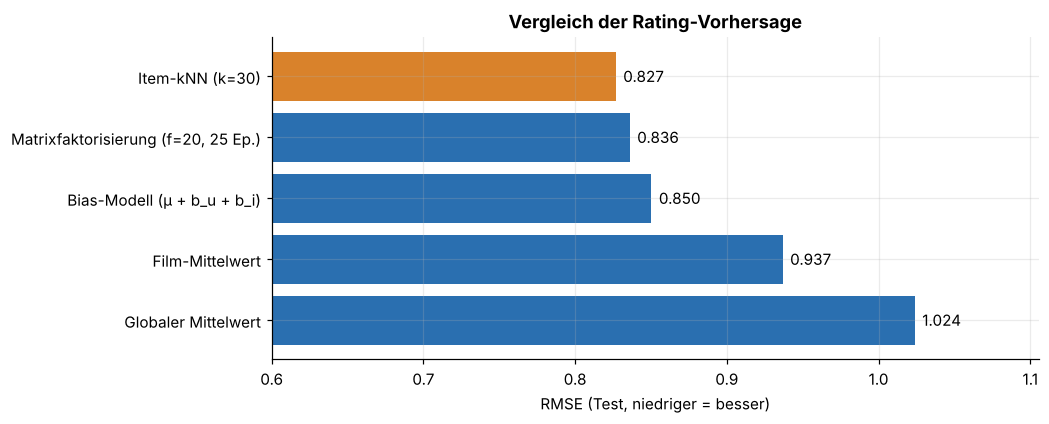

In [25]:
fig, ax = plt.subplots(figsize=(9, 3.8))
order = res_df.sort_values("RMSE", ascending=False)
colors = [ORANGE if r == res_df.RMSE.min() else BLAU for r in order.RMSE]
ax.barh(order.index, order.RMSE, color=colors)
for y_, v in enumerate(order.RMSE): ax.text(v + 0.005, y_, f"{v:.3f}", va="center")
ax.set_xlim(0.6, order.RMSE.max() * 1.08); ax.set_xlabel("RMSE (Test, niedriger = besser)")
ax.set_title("Vergleich der Rating-Vorhersage"); plt.show()

## 7. Evaluation als Ranking-Aufgabe (Top-N-Empfehlungen)

In der Praxis soll ein System nicht eine Note vorhersagen, sondern eine **Liste von Top-N-Filmen** liefern. Dafür sind Ranking-Metriken geeigneter:

* Ein Testfilm gilt als **relevant**, wenn der Nutzer ihn mit **≥ 4,0** bewertet hat.
* Kandidaten sind alle Filme (aus dem gefilterten Katalog), die der Nutzer im Training **noch nicht** bewertet hat.
* **Precision@10:** Anteil relevanter Filme unter den 10 Empfehlungen.
* **Recall@10:** Anteil aller relevanten Testfilme, die in den Top-10 gefunden wurden.
* **Hit-Rate@10:** Anteil der Nutzer, bei denen mindestens ein relevanter Film in den Top-10 steht.

Verglichen werden: **Zufall**, **Beliebtheit**, **Item-kNN** und **Matrixfaktorisierung**.

In [26]:
K = 10
REL = 4.0

# Scores: Matrix (Nutzer x Film), höher = besser
pop_score_item = (train.groupby("i").rating.agg(["count", "mean"]).reindex(range(n_i)).fillna(0))
m_ = pop_score_item["count"].quantile(0.9)
wr_ = pop_score_item["count"] / (pop_score_item["count"] + m_) * pop_score_item["mean"] + m_ / (pop_score_item["count"] + m_) * mu
score_pop = np.tile(wr_.values, (n_u, 1))

rs = np.random.RandomState(SEED)
score_rand = rs.rand(n_u, n_i)

# Item-kNN-Score: gewichtete Summe der zentrierten Bewertungen über ähnliche Filme (nur positive Ähnlichkeit)
Spos = np.clip(S, 0, None)
score_knn = (Rc @ Spos) / (M @ Spos + 1e-9)

# MF-Score
score_mf = mf_best["mu"] + mf_best["bu"][:, None] + mf_best["bi"][None, :] + mf_best["P"] @ mf_best["Q"].T

rel = test[test.rating >= REL].groupby("u").i.apply(set)

MIN_POP = 30   # Kandidaten-Untergrenze: nur Filme mit >= 30 Trainingsbewertungen werden empfohlen
cand_ok = (pop_score_item["count"].values >= MIN_POP)

def ranking_eval(score, only_popular=True):
    sc = np.where(M > 0, -np.inf, score)          # bereits gesehene Filme ausschließen
    if only_popular: sc = np.where(cand_ok[None, :], sc, -np.inf)
    prec, rec, hit = [], [], []
    for u, relset in rel.items():
        top = np.argpartition(-sc[u], K)[:K]
        found = len(set(top) & relset)
        prec.append(found / K); rec.append(found / len(relset)); hit.append(found > 0)
    return {f"Precision@{K}": np.mean(prec), f"Recall@{K}": np.mean(rec), f"Hit-Rate@{K}": np.mean(hit)}

# Hybrid: personalisierter MF-Score + Beliebtheit (beide je Nutzer z-standardisiert)
def zrow(a):
    a = np.where(cand_ok[None, :], a, np.nan)
    return (a - np.nanmean(a, 1, keepdims=True)) / np.nanstd(a, 1, keepdims=True)
score_hyb = np.nan_to_num(zrow(score_mf) + 1.0 * zrow(score_pop), nan=-9)

print("Ohne Kandidatenfilter (alle Filme mit >= 10 Bewertungen):")
print(pd.DataFrame({"Item-kNN": ranking_eval(score_knn, False), "Matrixfaktorisierung": ranking_eval(score_mf, False)}).T.round(4))
print()

rank_res = pd.DataFrame({
    "Zufall": ranking_eval(score_rand),
    "Beliebtheit (gewichtet)": ranking_eval(score_pop),
    "Item-kNN": ranking_eval(score_knn),
    "Matrixfaktorisierung": ranking_eval(score_mf),
    "Hybrid (MF + Beliebtheit)": ranking_eval(score_hyb),
}).T.round(4)
print(f"Mit Kandidatenfilter (>= {MIN_POP} Trainingsbewertungen) – ausgewertete Nutzer: {len(rel)}")
rank_res

Ohne Kandidatenfilter (alle Filme mit >= 10 Bewertungen):
                      Precision@10  Recall@10  Hit-Rate@10
Item-kNN                    0.0138     0.0076       0.1056
Matrixfaktorisierung        0.0164     0.0111       0.1210

Mit Kandidatenfilter (>= 30 Trainingsbewertungen) – ausgewertete Nutzer: 587


,Precision@10,Recall@10,Hit-Rate@10
Zufall,0.0186,0.0137,0.1465
Beliebtheit (gewichtet),0.1077,0.0847,0.5094
Item-kNN,0.0484,0.0268,0.2658
Matrixfaktorisierung,0.0557,0.0404,0.3186
Hybrid (MF + Beliebtheit),0.0913,0.0699,0.4600


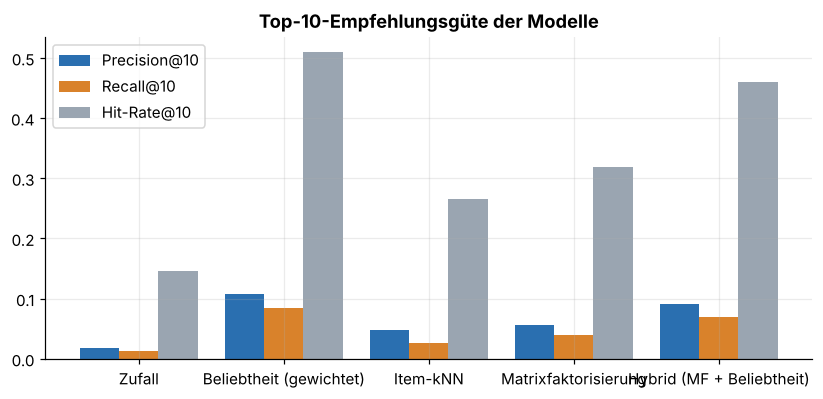

In [27]:
fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(rank_res)); w = 0.27
for j, (col, c) in enumerate(zip(rank_res.columns, [BLAU, ORANGE, GRAU])):
    ax.bar(x + (j - 1) * w, rank_res[col], w, label=col, color=c)
ax.set_xticks(x); ax.set_xticklabels(rank_res.index); ax.set_title("Top-10-Empfehlungsgüte der Modelle"); ax.legend()
plt.show()

**Interpretation:**

* **Kandidatenfilter ist entscheidend:** Ohne Untergrenze empfehlen kNN und MF vor allem *Nischenfilme mit wenigen, zufällig sehr guten Bewertungen* – die Trefferquote ist dann sehr niedrig (erste Tabelle). Mit der Untergrenze von 30 Bewertungen verbessern sich beide Modelle deutlich (zweite Tabelle). In der Praxis ist ein solcher Filter Standard.
* **Personalisierte Modelle schlagen den Zufall klar**, die Matrixfaktorisierung liegt vor Item-kNN.
* **Die Beliebtheitsbasis ist in diesem Test am stärksten.** Das ist ein bekannter Effekt bei Offline-Tests auf MovieLens: Nutzer bewerten überwiegend populäre Filme, deshalb liegen viele relevante Testfilme unter den Top-Hits. Auch der einfache Hybrid aus MF und Beliebtheit schlägt die reine Beliebtheit nicht. Die Aussage lautet also *nicht* „Personalisierung ist nutzlos“, sondern: Mit so wenig Daten (610 Nutzer, ~100.000 Bewertungen) und dieser Metrik ist die Beliebtheit schwer zu schlagen. Genau deshalb muss man gegen einfache Baselines evaluieren.

**Einschränkung der Evaluation:** Offline-Metriken messen nur, ob Nutzer Filme *tatsächlich bewertet haben*. Ein guter Empfohlener Film, den der Nutzer nie bewertet hat, zählt als „nicht relevant“. Die Werte unterschätzen daher die wahre Qualität aller Modelle (besonders der personalisierten, die Neues entdecken).

## 8. Finale Empfehlungsfunktionen

Zum Schluss fassen wir alles in nutzbaren Funktionen zusammen:

1. `empfehle_fuer_nutzer(user_id)`: personalisierte Top-N mit dem Matrixfaktorisierungsmodell, diesmal **auf allen Daten** trainiert.
2. `empfehle_aehnlich(titel)`: „Ähnlich wie …“ per kollaborativer Item-Ähnlichkeit.
3. `empfehle_neuer_nutzer(genres)`: **Cold-Start** für neue Nutzer – beliebteste Filme der gewählten Genres.

In [28]:
# Finales Modell auf ALLEN Daten (Train + Test) trainieren
mf_final, _ = train_mf(rf, n_factors=20, epochs=best_ep)

R_all = np.zeros((n_u, n_i)); R_all[rf.u, rf.i] = rf.rating
seen_all = R_all > 0
score_final = mf_final["mu"] + mf_final["bu"][:, None] + mf_final["bi"][None, :] + mf_final["P"] @ mf_final["Q"].T
movie_info = movies.set_index("movieId")
pop_ok_all = (seen_all.sum(axis=0) >= MIN_POP)     # nur Filme mit genug Bewertungen empfehlen

def empfehle_fuer_nutzer(user_id, n=10):
    """Personalisierte Top-n Filme, die der Nutzer noch nicht bewertet hat."""
    u = u_idx[user_id]
    sc = np.where(seen_all[u] | ~pop_ok_all, -np.inf, score_final[u])   # gesehene und zu selten bewertete Filme ausschließen
    top = np.argsort(-sc)[:n]
    out = pd.DataFrame({
        "Film": [movie_info.title[item_ids[i]] for i in top],
        "Genres": [movie_info.genres[item_ids[i]] for i in top],
        "Vorhergesagte Note": np.clip(sc[top], 0.5, 5).round(2),
    })
    return out.reset_index(drop=True)

def lieblingsfilme(user_id, n=5):
    d = rf[rf.userId == user_id].sort_values(["rating", "timestamp"], ascending=False).head(n)
    return pd.DataFrame({"Film": d.movieId.map(movie_info.title).values, "Genres": d.movieId.map(movie_info.genres).values, "Note": d.rating.values})

print("Lieblingsfilme von Nutzer 1:")
lieblingsfilme(1)

Lieblingsfilme von Nutzer 1:


,Film,Genres,Note
0,Tombstone (1993),Action|Drama|Western,5.0
1,Canadian Bacon (1995),Comedy|War,5.0
2,Pink Floyd: The Wall (1982),Drama|Musical,5.0
3,"Messenger: The Story of Joan of Arc, The (1999)",Drama|War,5.0
4,"Good Morning, Vietnam (1987)",Comedy|Drama|War,5.0


In [29]:
print("Empfehlungen für Nutzer 1:")
empfehle_fuer_nutzer(1, 10)

Empfehlungen für Nutzer 1:


,Film,Genres,Vorhergesagte Note
0,"Shawshank Redemption, The (1994)",Crime|Drama,5.00
1,Lawrence of Arabia (1962),Adventure|Drama|War,4.99
2,Rear Window (1954),Mystery|Thriller,4.98
3,Casablanca (1942),Drama|Romance,4.98
4,"Boondock Saints, The (2000)",Action|Crime|Drama|Thriller,4.95
5,"Boot, Das (Boat, The) (1981)",Action|Drama|War,4.95
6,Dr. Strangelove or: How I Learned to Stop Worrying and L...,Comedy|War,4.94
7,Rosemary's Baby (1968),Drama|Horror|Thriller,4.94
8,Cool Hand Luke (1967),Drama,4.93
9,"Godfather, The (1972)",Crime|Drama,4.93


In [30]:
print("Lieblingsfilme von Nutzer 414:")
display_df = lieblingsfilme(414)
display_df

Lieblingsfilme von Nutzer 414:


,Film,Genres,Note
0,"Secret Life of Walter Mitty, The (2013)",Adventure|Comedy|Drama,5.0
1,Seven Samurai (Shichinin no samurai) (1954),Action|Adventure|Drama,5.0
2,The Revenant (2015),Adventure|Drama,5.0
3,Spotlight (2015),Thriller,5.0
4,Dunkirk (2017),Action|Drama|Thriller|War,5.0


In [31]:
empfehle_fuer_nutzer(414, 10)

,Film,Genres,Vorhergesagte Note
0,Life Is Beautiful (La Vita è bella) (1997),Comedy|Drama|Romance|War,4.36
1,My Fair Lady (1964),Comedy|Drama|Musical|Romance,4.35
2,12 Angry Men (1957),Drama,4.33
3,Rosemary's Baby (1968),Drama|Horror|Thriller,4.32
4,"Lives of Others, The (Das leben der Anderen) (2006)",Drama|Romance|Thriller,4.30
5,"Shining, The (1980)",Horror,4.30
6,For a Few Dollars More (Per qualche dollaro in più) (1965),Action|Drama|Thriller|Western,4.27
7,Annie Hall (1977),Comedy|Romance,4.25
8,Psycho (1960),Crime|Horror,4.25
9,Manhattan (1979),Comedy|Drama|Romance,4.23


**Interpretation:** Die Empfehlungen passen zum Profil des jeweiligen Nutzers (Genre-Vorlieben, Qualitätsniveau) und enthalten ausschließlich ungesehene Filme. Nutzer mit unterschiedlichem Geschmack erhalten unterschiedliche Listen – im Gegensatz zum Beliebtheitsmodell.

In [32]:
def empfehle_aehnlich(titel, n=10):
    """Kollaborative Ähnlich-wie-Empfehlung (Item-Item)."""
    return aehnliche_filme(titel, n)

empfehle_aehnlich("Matrix, The (1999)", 8)

,Film,Ähnlichkeit,gemeinsame Bewerter
0,Pulp Fiction (1994),0.282,126
1,Fight Club (1999),0.282,120
2,Saving Private Ryan (1998),0.259,106
3,Die Hard (1988),0.253,86
4,Star Wars: Episode V - The Empire Strikes Back (1980),0.238,121
5,Reservoir Dogs (1992),0.237,80
6,Raiders of the Lost Ark (Indiana Jones and the Raiders o...,0.237,100
7,"Usual Suspects, The (1995)",0.235,94


In [33]:
def empfehle_neuer_nutzer(genres, n=10, min_votes=50):
    """Cold-Start: für neue Nutzer ohne Historie – beliebteste Filme in den gewählten Genres."""
    d = pop[pop.v >= min_votes]
    for g in genres:
        d = d[d.genres.str.contains(g, regex=False)]
    return d.head(n)[["title", "genres", "v", "WR"]].rename(columns={"title": "Film", "genres": "Genres", "v": "Anzahl", "WR": "Gewichtet"}).round(2).reset_index(drop=True)

empfehle_neuer_nutzer(["Sci-Fi", "Thriller"], 8)

,Film,Genres,Anzahl,Gewichtet
0,"Matrix, The (1999)",Action|Sci-Fi|Thriller,278,4.13
1,Blade Runner (1982),Action|Sci-Fi|Thriller,124,3.99
2,Inception (2010),Action|Crime|Drama|Mystery|Sci-Fi|Thriller|IMAX,143,3.98
3,Twelve Monkeys (a.k.a. 12 Monkeys) (1995),Mystery|Sci-Fi|Thriller,177,3.92
4,"Clockwork Orange, A (1971)",Crime|Drama|Sci-Fi|Thriller,120,3.91
5,"Prestige, The (2006)",Drama|Mystery|Sci-Fi|Thriller,90,3.89
6,Donnie Darko (2001),Drama|Mystery|Sci-Fi|Thriller,109,3.89
7,Gattaca (1997),Drama|Sci-Fi|Thriller,86,3.85


## 9. Fazit, Grenzen und Ausblick

### Ergebnisse im Überblick

| Aufgabe | Bestes Modell | Kennzahl |
|---|---|---|
| Rating-Vorhersage (Test) | **Item-kNN (k=30)** | RMSE ≈ 0,827 (Globaler Ø: 1,024; Bias-Modell: 0,850; Matrixfaktorisierung: 0,836) |
| Top-10-Ranking (Test) | **Beliebtheit (gewichtet)** | Precision@10 ≈ 0,108, Hit-Rate ≈ 51 % |
| Beste *personalisierte* Top-10 | Matrixfaktorisierung | Precision@10 ≈ 0,056, Hit-Rate ≈ 32 % (Zufall: 0,019 / 15 %) |

### Was wir gelernt haben

1. **Einfache Modelle sind starke Gegner.** Nutzer- und Film-Bias erklären schon einen Großteil der Varianz; die Beliebtheitsbasis ist bei Top-N sehr schwer zu schlagen.
2. **Kollaboratives Filtern verbessert die Vorhersagegüte** (RMSE) messbar und liefert erklärbare, überraschendere Empfehlungen als reine Genre-Ähnlichkeit.
3. **Datenqualität und Filter zählen:** Mindestanzahl an Bewertungen, Shrinkage und Regularisierung verhindern, dass Zufallstreffer bei wenig bewerteten Filmen dominieren.
4. **Cold-Start** (neue Nutzer / neue Filme) erfordert Alternativen: Beliebtheit je Genre bzw. inhaltsbasierte Ähnlichkeit.

### Grenzen

* Kleiner Datensatz (610 Nutzer), nur explizite Bewertungen.
* Offline-Evaluation mit einem einzigen zufälligen Split; Hyperparameter wurden nicht mit separatem Validierungsset optimiert.
* Inhaltsbasiertes Modell nutzt nur Genres (keine Schauspieler, Regie, Handlung).
* Metriken messen nur *bekannte* Bewertungen, nicht, ob ein Nutzer eine Empfehlung wirklich mögen würde.

### Ausblick

* Kreuzvalidierung, Grid-Search für Faktoren/Regularisierung, zeitbasierter Split.
* Hybridmodelle (kollaborativ + inhaltsbasiert), Genre-/Jahres-Features in der Faktorisierung.
* Implizites Feedback, ALS, neuronale Verfahren (z. B. Neural Collaborative Filtering).
* Zusätzliche Metriken: NDCG, Abdeckung (Coverage), Vielfalt (Diversity), Neuheit (Novelty).
* Bereitstellung als kleine Web-App (z. B. Streamlit).